In [1]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Styling for clean graphs
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

In [2]:
# ==========================================
# 2. LOAD AND INSPECT DATA
# ==========================================
df = pd.read_csv('car data.csv')
print("Dataset Shape:", df.shape)
display(df.head())
print("\nMissing Values:\n", df.isnull().sum())
print("\nDataset Info:")
df.info()

Dataset Shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0



Missing Values:
 Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Selling_type   301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB


In [3]:
# ==========================================
# 3. FEATURE ENGINEERING & PREPROCESSING
# ==========================================
# Calculate the age of the car based on the current year (e.g., 2026)
current_year = 2026
df['Car_Age'] = current_year - df['Year']

# Drop original 'Year' and 'Car_Name' (Car_Name has too many unique categorical values for standard OHE)
df_model = df.drop(['Car_Name', 'Year'], axis=1) #df.drop(cloumns = ['Car_Name', 'Year'])

# Convert categorical variables using One-Hot Encoding
df_model = pd.get_dummies(df_model, drop_first=True)

print("\nProcessed Feature Columns:", df_model.columns.tolist())
display(df_model.head())


Processed Feature Columns: ['Selling_Price', 'Present_Price', 'Driven_kms', 'Owner', 'Car_Age', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Selling_type_Individual', 'Transmission_Manual']


,Selling_Price,Present_Price,Driven_kms,Owner,Car_Age,Fuel_Type_Diesel,Fuel_Type_Petrol,Selling_type_Individual,Transmission_Manual
0,3.35,5.59,27000,0,12,False,True,False,True
1,4.75,9.54,43000,0,13,True,False,False,True
2,7.25,9.85,6900,0,9,False,True,False,True
3,2.85,4.15,5200,0,15,False,True,False,True
4,4.60,6.87,42450,0,12,True,False,False,True


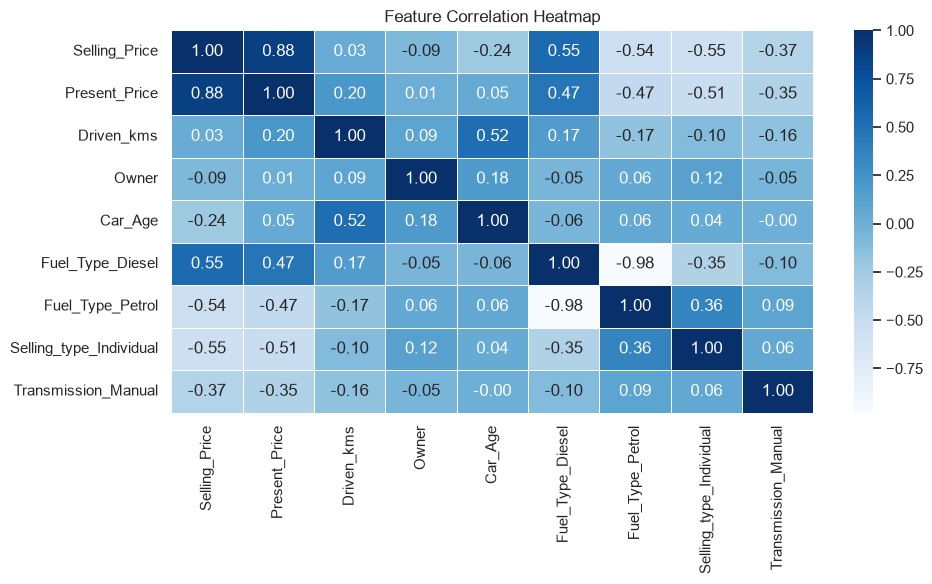

In [10]:
# ==========================================
# 4. EXPLORATORY DATA ANALYSIS (EDA) & VISUALIZATIONS
# ==========================================
# Correlation Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(df_model.corr(), annot=True, cmap='Blues', fmt='.2f', linewidths=0.6)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.savefig('correlation_heatmap.png')
plt.show()

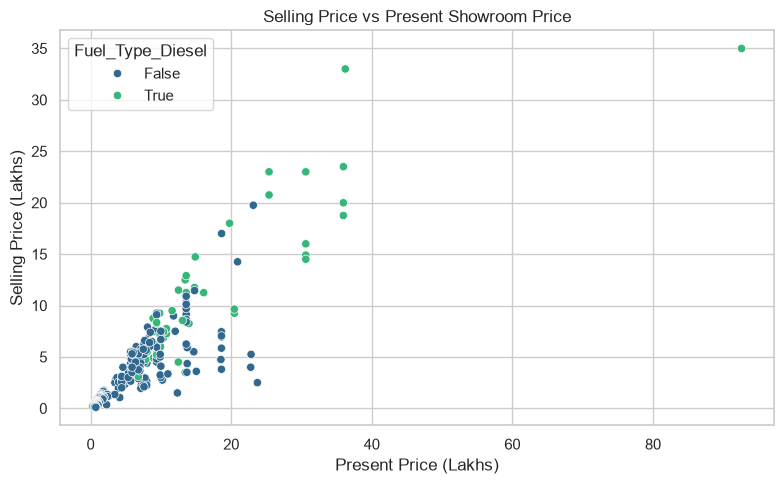

In [17]:
# Selling Price vs Present Price
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Present_Price', y='Selling_Price', hue='Fuel_Type_Diesel'  if 'Fuel_Type_Diesel' in df_model.columns else None, data=df_model, palette='viridis')
plt.title('Selling Price vs Present Showroom Price')
plt.xlabel('Present Price (Lakhs)')
plt.ylabel('Selling Price (Lakhs)')
plt.tight_layout()
plt.savefig('price_vs_showroom.png')
plt.show()

In [15]:
# ==========================================
# 5. MODEL TRAINING & EVALUATION
# ==========================================
# Define features (X) and target (y)
X = df_model.drop('Selling_Price', axis=1)
y = df_model['Selling_Price']

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    results.append({"Model": name, "MAE": mae, "RMSE": rmse, "R2 Score": r2})

results_df = pd.DataFrame(results)
print("\n--- Model Performance Comparison ---")
display(results_df)

Task was destroyed but it is pending!
task: <Task pending name='Task-127' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\praka\AppData\Local\Programs\Python\Python314\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-128' coro=<Kernel.shell_main() running at C:\Users\praka\AppData\Local\Programs\Python\Python314\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\praka\AppData\Local\Programs\Python\Python314\Lib\site-packages\zmq\eventloop\zmqstream.py:563]>
C:\Users\praka\AppData\Local\Programs\Python\Python314\Lib\site-packages\narwhals\_pandas_like\namespace.py:16: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  from narwhals._pandas_like.dataframe import PandasLikeDataFrame
Task was destroyed but it is pending!
task: <Task pending name='Task-128' coro=<Kernel.shell_main() running at C:\Users\praka\AppData\Local\Programs\Python\Pyt


--- Model Performance Comparison ---


,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.216374,1.865838,0.848871
1,Ridge Regression,1.211573,1.858826,0.850004
2,Random Forest,0.649421,0.977369,0.958532
3,Gradient Boosting,0.589875,0.939418,0.961689


C:\Users\praka\AppData\Local\Temp\ipykernel_27400\961605178.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='crest')


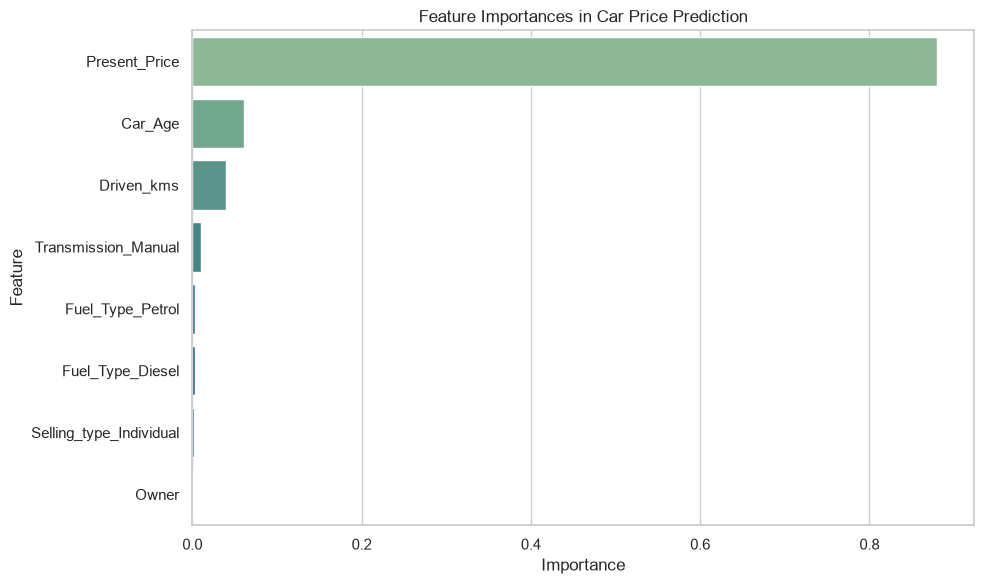

In [16]:
# ==========================================
# 6. FEATURE IMPORTANCE (Random Forest)
# ==========================================
rf_model = models["Random Forest"]
importances = rf_model.feature_importances_
feature_imp_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='crest')
plt.title('Feature Importances in Car Price Prediction')
plt.tight_layout()
plt.savefig('feature_importance.png')
plt.show()